In [1]:
!pip install catboost

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.13/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

import xgboost as xgb
import lightgbm as lgb
import catboost as cb

sns.set_theme(style="whitegrid")

In [3]:
data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(X.head())
print()
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"Размер обучающей выборки: {X_train.shape[0]}")
print(f"Размер валидационной выборки: {X_val.shape[0]}")
print(f"Размер тестовой выборки: {X_test.shape[0]}")

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Размер обучающей выборки: 12384
Размер валидационной выборки: 4128
Размер тестовой выборки: 4128


/home/maksim/Programming/ML/ml-course-homeworks/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


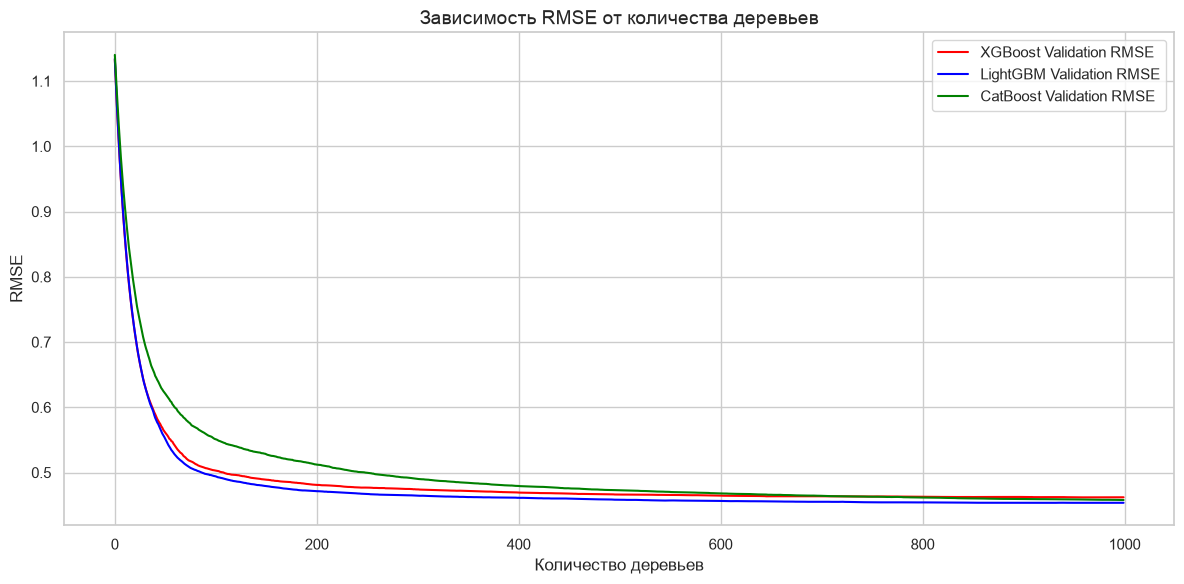

In [4]:
MAX_TREES = 1000
LEARNING_RATE = 0.05

xgb_model = xgb.XGBRegressor(n_estimators=MAX_TREES, learning_rate=LEARNING_RATE, random_state=42)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
xgb_rmse = xgb_model.evals_result()['validation_0']['rmse']

lgb_model = lgb.LGBMRegressor(n_estimators=MAX_TREES, learning_rate=LEARNING_RATE, random_state=42, verbose=-1)
lgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric='rmse')
lgb_metric_key = list(lgb_model.evals_result_['valid_0'].keys())[0]
lgb_rmse = lgb_model.evals_result_['valid_0'][lgb_metric_key]

cb_model = cb.CatBoostRegressor(iterations=MAX_TREES, learning_rate=LEARNING_RATE, eval_metric='RMSE', random_seed=42)
cb_model.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=False)
cb_rmse = cb_model.evals_result_['learn']['RMSE']
cb_val_rmse = cb_model.evals_result_['validation']['RMSE']

plt.figure(figsize=(12, 6))
plt.plot(xgb_rmse, label='XGBoost Validation RMSE', color='red')
plt.plot(lgb_rmse, label='LightGBM Validation RMSE', color='blue')
plt.plot(cb_val_rmse, label='CatBoost Validation RMSE', color='green')

plt.title('Зависимость RMSE от количества деревьев', fontsize=14)
plt.xlabel('Количество деревьев', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import ParameterGrid

SELECTED_N_ESTIMATORS = 100
X_train_full = pd.concat([X_train, X_val])
y_train_full = np.concatenate([y_train, y_val])

grid_xgb = {
    'learning_rate': [0.05, 0.1],
    'max_depth':[5, 7],
    'subsample': [0.8, 1.0]
}

grid_lgb = {
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 127],
    'subsample':[0.8, 1.0]
}

grid_cat = {
    'learning_rate':[0.05, 0.1],
    'depth': [5, 7],
    'subsample':[0.8, 1.0]
}

def simple_grid_search(model_name, param_grid):
    print(f"--- Запуск Grid Search для {model_name} ---")
    best_rmse = float('inf')
    best_params = None

    start_time = time.time()

    for params in ParameterGrid(param_grid):
        if model_name == 'XGBoost':
            model = xgb.XGBRegressor(**params, n_estimators=SELECTED_N_ESTIMATORS, random_state=42, n_jobs=-1)
        elif model_name == 'LightGBM':
            model = lgb.LGBMRegressor(**params, n_estimators=SELECTED_N_ESTIMATORS, random_state=42, n_jobs=-1, verbose=-1)
        else:
            model = cb.CatBoostRegressor(**params, iterations=SELECTED_N_ESTIMATORS, random_seed=42, thread_count=-1, verbose=0)

        model.fit(X_train, y_train)
        preds = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))

        if rmse < best_rmse:
            best_rmse = rmse
            best_params = params

    total_time = time.time() - start_time
    print(f"Лучший Validation RMSE: {best_rmse:.4f}")
    print(f"Лучшие параметры: {best_params}\n")

    return best_params

best_params_dict = {}
best_params_dict['XGBoost'] = simple_grid_search('XGBoost', grid_xgb)
best_params_dict['LightGBM'] = simple_grid_search('LightGBM', grid_lgb)
best_params_dict['CatBoost'] = simple_grid_search('CatBoost', grid_cat)

--- Запуск Grid Search для XGBoost ---


Лучший Validation RMSE: 0.4763
Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 7, 'subsample': 0.8}

--- Запуск Grid Search для LightGBM ---


Лучший Validation RMSE: 0.4621
Лучшие параметры: {'learning_rate': 0.1, 'num_leaves': 127, 'subsample': 0.8}

--- Запуск Grid Search для CatBoost ---


Лучший Validation RMSE: 0.4999
Лучшие параметры: {'depth': 7, 'learning_rate': 0.1, 'subsample': 1.0}



In [6]:
results = []

for name in['XGBoost', 'LightGBM', 'CatBoost']:
    params = best_params_dict.get(name)

    if name == 'XGBoost':
        model = xgb.XGBRegressor(n_estimators=SELECTED_N_ESTIMATORS, random_state=42, n_jobs=-1, **params)
    elif name == 'LightGBM':
        model = lgb.LGBMRegressor(n_estimators=SELECTED_N_ESTIMATORS, random_state=42, n_jobs=-1, verbose=-1, **params)
    else:
        model = cb.CatBoostRegressor(iterations=SELECTED_N_ESTIMATORS, random_seed=42, thread_count=-1, verbose=0, **params)

    start_time = time.time()
    model.fit(X_train_full, y_train_full)
    train_time = time.time() - start_time

    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results.append({
        "Модель": name,
        "Время обучения": round(train_time, 3),
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2 Score": round(r2, 4)
    })

df_results = pd.DataFrame(results)
display(df_results)

,Модель,Время обучения,MAE,RMSE,R2 Score
0,XGBoost,0.129,0.3066,0.4648,0.8351
1,LightGBM,0.271,0.2918,0.4459,0.8483
2,CatBoost,0.149,0.3437,0.5081,0.8030


### Реализация собственного градиентного бустинга
Мы реализуем регрессор `SimpleGBM`, который поддерживает:
1. `subsample`: Случайная подвыборка строк для каждого дерева.
2. `colsample_bytree`: Случайная подвыборка признаков для каждого дерева.
3. `feature_importances_`: Агрегированная важность признаков на основе базовых моделей.

In [7]:
class SimpleGBM:
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3, subsample=1.0, colsample_bytree=1.0, cat_features=None, random_state=42):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.cat_features = cat_features
        self.random_state = random_state
        self.trees = []
        self.base_pred = None
        self.features_idx = []
        self._feature_importances = None

    def fit(self, X, y):
        X = pd.DataFrame(X).copy()
        if self.cat_features:
            for col in self.cat_features:
                X[col] = X[col].astype('category').cat.codes

        rng = np.random.default_rng(self.random_state)
        n_samples, n_features = X.shape
        self.base_pred = np.mean(y)
        y_pred = np.full(n_samples, self.base_pred)
        importances = np.zeros(n_features)

        for i in range(self.n_estimators):
            residuals = y - y_pred
            indices = rng.choice(n_samples, int(self.subsample * n_samples), replace=False)
            cols = rng.choice(n_features, int(self.colsample_bytree * n_features), replace=False)
            self.features_idx.append(cols)

            tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=self.random_state + i)
            tree.fit(X.iloc[indices, cols], residuals[indices])
            self.trees.append(tree)

            y_pred += self.learning_rate * tree.predict(X.iloc[:, cols])
            importances[cols] += tree.feature_importances_ * self.learning_rate

        self._feature_importances = importances / self.n_estimators

    @property
    def feature_importances_(self):
        return self._feature_importances

    def predict(self, X):
        X = pd.DataFrame(X).copy()
        if self.cat_features:
            for col in self.cat_features:
                X[col] = X[col].astype('category').cat.codes

        y_pred = np.full(X.shape[0], self.base_pred)
        for tree, cols in zip(self.trees, self.features_idx):
            y_pred += self.learning_rate * tree.predict(X.iloc[:, cols])
        return y_pred


R2 Score собственного GBM: 0.8168
Лучший R2 Score библиотек: 0.8483
Разница: 0.0315


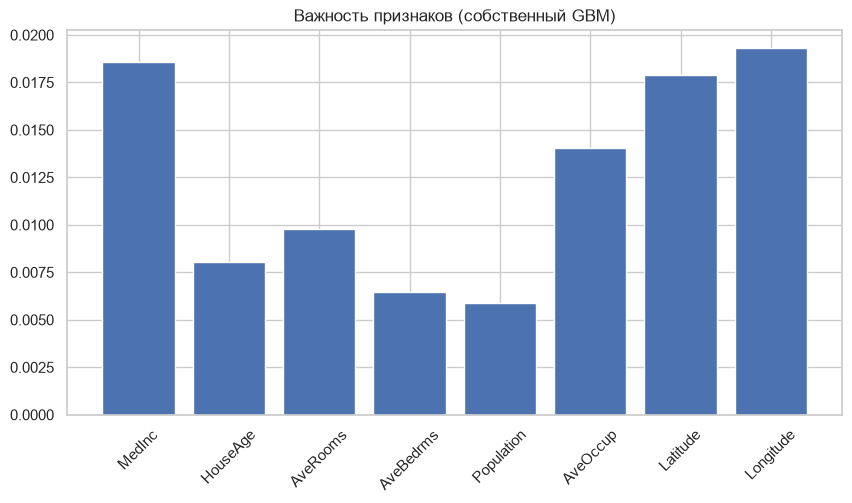

In [8]:
# Обучение и оценка собственного GBM
custom_gbm = SimpleGBM(n_estimators=100, learning_rate=0.1, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=42)
custom_gbm.fit(X_train, y_train)

custom_preds = custom_gbm.predict(X_test)
custom_r2 = r2_score(y_test, custom_preds)

print(f'R2 Score собственного GBM: {custom_r2:.4f}')

if 'df_results' in locals() and not df_results.empty:
    lib_best_r2 = df_results['R2 Score'].max()
    print(f'Лучший R2 Score библиотек: {lib_best_r2:.4f}')
    print(f'Разница: {lib_best_r2 - custom_r2:.4f}')

plt.figure(figsize=(10, 5))
plt.bar(X.columns, custom_gbm.feature_importances_)
plt.title('Важность признаков (собственный GBM)')
plt.xticks(rotation=45)
plt.show()
